# Review 2 — Method 2

Member 2 Part A: corpus, tone, complexity and interpretation. **Member 4 Part B (topics and keywords) is supplied separately. Human labels remain an explicit dependency.**

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())


## Corpus preparation and audit

In [2]:
TEXT=ROOT/'reports/review2/text'
assert json.loads((TEXT/'corpus_stats.json').read_text())['documents_after']==302026
display(json.loads((TEXT/'corpus_stats.json').read_text()))
display(json.loads((TEXT/'text_preprocessing.json').read_text()))
display(pd.read_parquet(TEXT/'corpus_sample_metadata.parquet').head(8))

{'documents_before': 302026,
 'documents_after': 302026,
 'empty_after_cleaning': 0,
 'vocabulary_size': 165887,
 'total_tokens': 14312333,
 'spacy_model': 'en_core_web_sm',
 'parser_ner': 'disabled',
 'code_excluded': True,
 'sampling_weight': 'retained, must be used in shares',
 'seconds': 418.75}

{'technology_tokens': {'c++': 'cplusplus',
  'c#': 'csharp',
  '.net': 'dotnet',
  'node.js': 'nodejs',
  'next.js': 'nextjs',
  'vue.js': 'vuejs',
  'asp.net': 'aspnet'},
 'stopwords': ["'d",
  "'ll",
  "'m",
  "'re",
  "'s",
  "'ve",
  'a',
  'about',
  'above',
  'across',
  'after',
  'afterwards',
  'again',
  'against',
  'all',
  'almost',
  'alone',
  'along',
  'already',
  'also',
  'although',
  'always',
  'am',
  'among',
  'amongst',
  'amount',
  'an',
  'and',
  'another',
  'any',
  'anyhow',
  'anyone',
  'anything',
  'anyway',
  'anywhere',
  'are',
  'around',
  'as',
  'at',
  'back',
  'be',
  'became',
  'because',
  'become',
  'becomes',
  'becoming',
  'been',
  'before',
  'beforehand',
  'behind',
  'being',
  'below',
  'beside',
  'besides',
  'between',
  'beyond',
  'both',
  'bottom',
  'but',
  'by',
  'ca',
  'call',
  'can',
  'cannot',
  'could',
  'did',
  'do',
  'does',
  'doing',
  'done',
  'down',
  'due',
  'during',
  'each',
  'eight',
  '

,question_id,created_at,tags,sampling_weight,target_resolved_7d,period,n_tokens,title,link
0,76680934,2023-07-13 15:09:46+00:00,"[powerbi, slicers]",1.0,0,post,29,How to auto select other 2 in a slicer when I ...,https://stackoverflow.com/q/76680934
1,61554380,2020-05-02 04:15:43+00:00,"[r, machine-learning, split, sample-data]",10.0,0,pre,41,How to sample small set of images for training...,https://stackoverflow.com/q/61554380
2,63254502,2020-08-04 20:20:18+00:00,"[javascript, reactjs, redux, react-redux, mern]",21.0,1,pre,47,Creating a put api request using Redux,https://stackoverflow.com/q/63254502
3,70956590,2022-02-02 13:35:23+00:00,"[python, seaborn]",20.0,0,pre,18,Highlight elements on heatmap using Python,https://stackoverflow.com/q/70956590
4,63107357,2020-07-27 01:02:02+00:00,"[javascript, r, shiny]",23.0,1,pre,23,How to force shiny input to be capitalized,https://stackoverflow.com/q/63107357
5,66844549,2021-03-28 18:03:13+00:00,"[javascript, html5-audio, web-audio-api]",8.0,1,pre,35,Muting sound output when using Mic - Audio Web...,https://stackoverflow.com/q/66844549
6,75992973,2023-04-12 07:32:16+00:00,"[sql, pyspark, etl, aws-glue, predicate]",20.0,0,post,43,Pushdown predicate between two date ranges if ...,https://stackoverflow.com/q/75992973
7,79653142,2025-06-04 16:11:52+00:00,"[android, kotlin, android-custom-view]",1.0,0,post,34,Visibility Attribute and onclick event not wor...,https://stackoverflow.com/q/79653142


## Tone on original prose, without code
Technical-word overrides are written down; lowercase clean topic text is not used for VADER.

In [3]:
display(json.loads((TEXT/'tone_method.json').read_text()))
display(pd.read_csv(TEXT/'tone_monthly.csv').head(10))
display(pd.read_csv(TEXT/'tone_prepost.csv').query("tag == 'ALL'"))

{'technical_word_overrides': ['kill',
  'fatal',
  'execute',
  'master',
  'abort',
  'dead',
  'failed',
  'exception',
  'error'],
 'frustration_regex': '\\burgent\\b|\\basap\\b|\\bstuck\\b|\\bfrustrat\\w*\\b|\\bfor (?:hours|days)\\b|\\bdesperate\\b|\\bnothing works\\b|\\bplease help\\b',
 'politeness_regex': '\\bthanks\\b|\\bthank you\\b|\\bappreciat\\w*\\b',
 'thresholds': {'positive': '>=0.05',
  'negative': '<=-0.05',
  'neutral': 'otherwise'},
 'label_rule': "Label the human asker's emotional tone as negative (expressed frustration/anger/distress), positive (expressed satisfaction/optimism/gratitude), or neutral (factual technical question without clear emotion). Technical error words alone are neutral. Do not use answer outcomes or the model score. Read the title and original question prose, ignoring code. Label independently before comparing.",
 'code_excluded': True,
 'warning': 'VADER is exploratory until independently human validated; no human labels are generated by code'

,tag,month,period,n_sampled,low_sample,negative_share,neutral_share,positive_share,frustration_flag_share,politeness_flag_share
0,ALL,2019-01,pre,4314,False,0.215858,0.080775,0.703367,0.043016,0.189923
1,ALL,2019-02,pre,4732,False,0.218167,0.070817,0.711016,0.059083,0.214329
2,ALL,2019-03,pre,4744,False,0.217897,0.081716,0.700387,0.042256,0.204239
3,ALL,2019-04,pre,4487,False,0.202331,0.078231,0.719438,0.043598,0.179721
4,ALL,2019-05,pre,4569,False,0.227093,0.072465,0.700443,0.047707,0.162119
5,ALL,2019-06,pre,4091,False,0.222263,0.080279,0.697458,0.040932,0.172883
6,ALL,2019-07,pre,4359,False,0.220875,0.075217,0.703908,0.039911,0.177244
7,ALL,2019-08,pre,4193,False,0.209912,0.072788,0.717301,0.045067,0.181804
8,ALL,2019-09,pre,3931,False,0.218215,0.082699,0.699086,0.044825,0.157295
9,ALL,2019-10,pre,4363,False,0.220997,0.079351,0.699652,0.049381,0.192348


,tag,measure,pre,post,change,lower95,upper95,bootstrap_resamples
0,ALL,negative,0.209487,0.236663,0.027176,0.021937,0.032179,1000
1,ALL,neutral,0.079173,0.072314,-0.006858,-0.009828,-0.003590,1000
2,ALL,positive,0.711341,0.691023,-0.020318,-0.025603,-0.015084,1000
3,ALL,frustration,0.050643,0.048570,-0.002073,-0.004611,0.000360,1000
4,ALL,politeness,0.208315,0.178995,-0.029320,-0.033888,-0.024433,1000


## Independent human validation — pending
Two humans label negative/neutral/positive independently, then agree on final labels. No synthetic human labels are generated.

In [4]:
status=json.loads((TEXT/'tone_validation_status.json').read_text())
display(status)
display(pd.read_csv(TEXT/'tone_validation.csv'))
if status['status']=='complete':
    display(pd.read_csv(TEXT/'tone_confusion.csv'))
else:
    print('Accuracy, macro-F1 and kappa cannot be reported until all 200 questions have independent labels.')

{'status': 'awaiting_independent_human_labels',
 'labelled_rows': 0,
 'required_rows': 200,
 'accuracy': None,
 'macro_f1': None,
 'cohen_kappa': None}

,status,labelled_rows,required_rows,accuracy,macro_f1,cohen_kappa
0,awaiting_independent_human_labels,0,200,NaN,NaN,NaN


Accuracy, macro-F1 and kappa cannot be reported until all 200 questions have independent labels.


## Complexity and weighted pre/post uncertainty
Flesch is a prose-reading proxy and technical vocabulary can limit interpretation. Empty prose is not assigned a readability score.

{'readability': 'textstat Flesch reading ease on prose only; technical vocabulary limits interpretation',
 'bootstrap': '1000 question resamples with replacement; retain sampling_weight; compressed identical value/weight cells',
 'periods': 'pre <= 2022-10, transition 2022-11/12 excluded from contrast, post >= 2023-01',
 'flags': 'case-insensitive error; leading why/how; dotted numeric version; >=2 study tags',
 'empty_prose': 'Flesch undefined (NaN), not zero',
 'low_sample': 'monthly flag for <30 sampled questions'}

,tag,metric,statistic,pre,post,change,lower95,upper95,n_pre,n_post,bootstrap_resamples
0,ALL,prose_words,median,76.000000,89.000000,13.000000,12.000000,13.000000,207162,87619,1000
1,ALL,code_lines,median,16.000000,20.000000,4.000000,3.000000,4.000000,207162,87619,1000
2,ALL,n_code_blocks,median,1.000000,1.000000,0.000000,0.000000,1.000000,207162,87619,1000
3,ALL,tag_count,median,3.000000,3.000000,0.000000,0.000000,0.000000,207162,87619,1000
4,ALL,flesch_reading_ease,median,67.050000,64.540000,-2.510000,-2.700000,-2.320000,207162,87619,1000
5,ALL,error_text_flag,mean,0.234327,0.274250,0.039923,0.035075,0.045076,207162,87619,1000
6,ALL,why_how_flag,mean,0.260615,0.250686,-0.009928,-0.015069,-0.005014,207162,87619,1000
7,ALL,version_flag,mean,0.076325,0.105564,0.029239,0.025899,0.032733,207162,87619,1000
8,ALL,multi_technology_flag,mean,0.227622,0.194068,-0.033554,-0.038152,-0.028698,207162,87619,1000


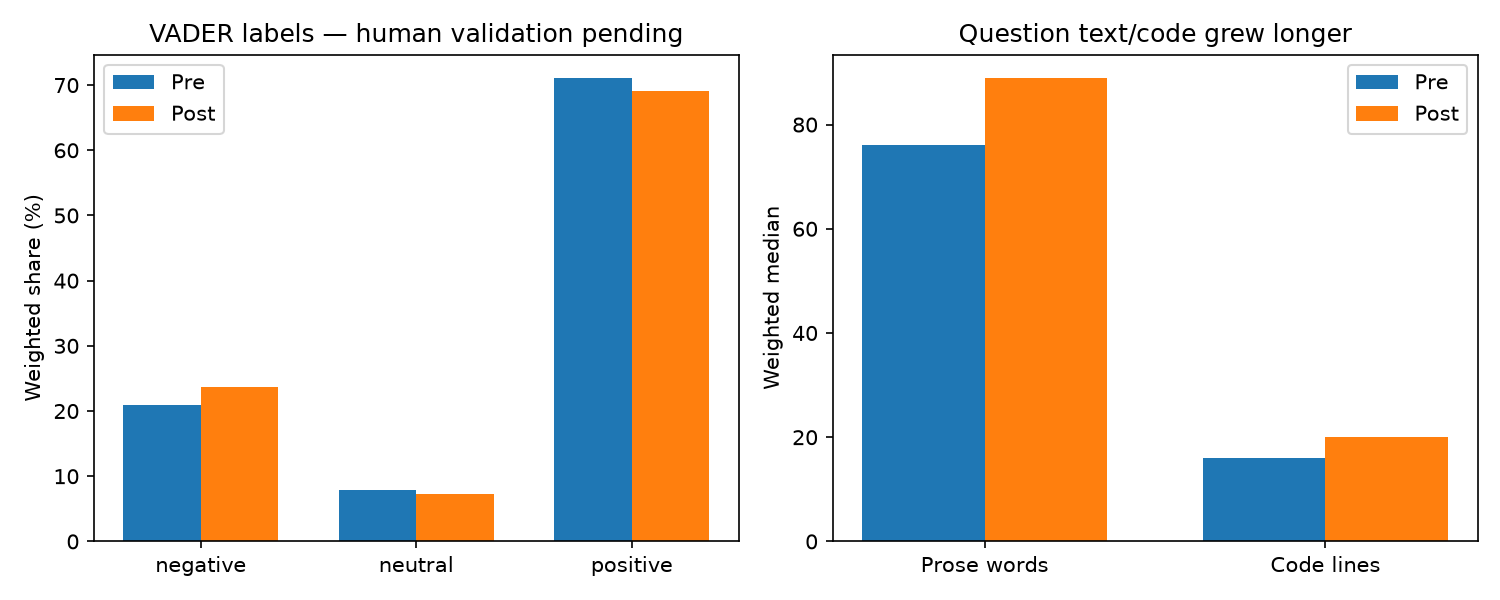

In [5]:
display(json.loads((TEXT/'complexity_method.json').read_text()))
display(pd.read_csv(TEXT/'complexity_prepost.csv').query("tag == 'ALL'"))
display(Image(filename=str(TEXT/'tone_complexity.png')))

## Exploratory association with resolution
Weighted logistic regression controls for full study-tag indicators and year. The coefficients are associations, not causal effects.

In [6]:
display(pd.read_csv(TEXT/'tone_resolution_association.csv'))

,term,coefficient,odds_ratio,lower95,upper95,p_value
0,const,-0.285507,0.751633,0.716941,0.788005,2.375759e-32
1,negative,0.009457,1.009501,0.972887,1.047494,6.158839e-01
2,positive,0.117569,1.124760,1.087836,1.162936,5.072457e-12
3,frustration,-0.189152,0.827661,0.794662,0.862029,8.086101e-20
4,tag_android,-0.367772,0.692275,0.666041,0.719543,1.082109e-77
5,tag_docker,-0.365890,0.693579,0.651427,0.738459,2.717593e-30
6,tag_excel,-0.164189,0.848581,0.801962,0.897911,1.232411e-08
7,tag_fastapi,-0.270024,0.763361,0.724315,0.804513,6.795929e-24
8,tag_java,-0.135807,0.873011,0.841924,0.905246,2.119104e-13
9,tag_javascript,0.112624,1.119211,1.083290,1.156324,1.318443e-11


## Findings and handoff

In [7]:
print((ROOT/'reports/review2/m2_findings.md').read_text())
display(json.loads((TEXT/'dashboard_handoff.json').read_text()))

# Member 2: tone and complexity findings

- Prepared 302,026 prose-only documents; 0 are empty after cleaning, and vocabulary contains 165,887 terms.
- Weighted median prose length changed from 76 to 89 words; difference 13, with 95% question-bootstrap interval [12, 13].
- Weighted median code lines changed from 16 to 20; difference 4, with 95% interval [3, 4].
- The written frustration-phrase flag changed from 5.1% to 4.9%; this is a lexicon measure, not independently verified emotion.
- Questions with at least two study tags changed from 22.8% to 19.4%; share-change 95% interval [-3.82, -2.87] percentage points.

VADER accuracy, macro-F1 and rater kappa are pending 200 independent human labels. Do not claim model validation or AI causality from these outputs.



{'owner': 'M2 Rishiikesh',
 'schemas': {'complexity_monthly.csv': ['tag',
   'month',
   'period',
   'n_sampled',
   'low_sample',
   'prose_words_median',
   'code_lines_median',
   'n_code_blocks_median',
   'tag_count_median',
   'flesch_reading_ease_median',
   'error_text_flag_share',
   'why_how_flag_share',
   'version_flag_share',
   'multi_technology_flag_share'],
  'tone_prepost.csv': ['tag',
   'measure',
   'pre',
   'post',
   'change',
   'lower95',
   'upper95',
   'bootstrap_resamples'],
  'dashboard_captions.csv': ['chart', 'file', 'takeaway', 'caveat'],
  'complexity_prepost.csv': ['tag',
   'metric',
   'statistic',
   'pre',
   'post',
   'change',
   'lower95',
   'upper95',
   'n_pre',
   'n_post',
   'bootstrap_resamples'],
  'tone_resolution_association.csv': ['term',
   'coefficient',
   'odds_ratio',
   'lower95',
   'upper95',
   'p_value'],
  'tone_validation_sample.csv': ['question_id',
   'period',
   'title',
   'link',
   'label_m2',
   'label_m3',
   '

## Part B — Nishanth’s topic models and keywords
Insert reviewed topic selection, stability, human topic naming and trends here. Rishiikesh can supply topic names only after the topic terms/examples exist.